In [12]:
# %% [Ticket Step 1: Import Libraries & Setup NLP Preprocessors]
import os
import re
import json
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import nltk

plt.style.use("ggplot")
pd.set_option("display.max_columns", None)
np.random.seed(42)

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectPercentile, chi2
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

for pkg in ["punkt", "punkt_tab", "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng", "maxent_ne_chunker", "maxent_ne_chunker_tab", "words"]:
    nltk.download(pkg, quiet=True)

EMOJI_MAP = {
    "😍": " emoji_love_excellent ", "😊": " emoji_happy_satisfied ", "👍": " emoji_thumbs_up_good ",
    "🙏": " emoji_grateful_thank_you ", "😐": " emoji_neutral_average ", "😢": " emoji_crying_sad_pain ",
    "😭": " emoji_sobbing_very_sad ", "😡": " emoji_angry_furious_worst ", "👎": " emoji_thumbs_down_poor ",
    ":)": " emoji_happy_good ", ":(": " emoji_sad_dissatisfied "
}

SLANG_ABBR_MAP = {
    r"\bgr8\b": "great", r"\bgud\b": "good", r"\bvry\b": "very", r"\bpls\b": "please",
    r"\bhrs\b": "hours", r"\bhr\b": "hour", r"\bmins\b": "minutes", r"\bopd\b": "outpatient department",
    r"\bappt\b": "appointment", r"\bdoc\b": "doctor", r"\bdr\b": "doctor", r"\blab\b": "laboratory",
    r"\bdissatisifed\b": "dissatisfied", r"\btkt\b": "ticket"
}

def clean_and_expand_text(text: str) -> str:
    if not text:
        return ""
    s = str(text)
    for emo, rep in EMOJI_MAP.items():
        s = s.replace(emo, rep)
    s = s.lower()
    for pat, rep in SLANG_ABBR_MAP.items():
        s = re.sub(pat, rep, s)
    s = re.sub(r"[^a-z0-9_\s]", " ", s)
    return re.sub(r"\s+", " ", s).strip()

class HospitalDomainFeatureExtractor(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        feats = []
        pos_w = {"excellent", "good", "great", "polite", "caring", "clean", "resolved", "solved", "helpful", "smooth", "quick", "satisfied", "supportive", "emoji_happy_satisfied", "emoji_love_excellent", "emoji_thumbs_up_good"}
        neg_w = {"waited", "slow", "delay", "delayed", "rude", "dirty", "worst", "terrible", "poor", "unacceptable", "ignored", "misplaced", "late", "crowded", "disappointed", "dissatisfied", "escalated", "unresolved", "complaint", "emoji_angry_furious_worst", "emoji_crying_sad_pain", "emoji_thumbs_down_poor"}
        neu_w = {"okay", "average", "routine", "standard", "normal", "moderate", "acceptable", "fair", "decent", "satisfactory", "emoji_neutral_average"}
        contrast_w = {"but", "however", "though", "although", "except"}
        for text in X:
            tokens = str(text).lower().split()
            p_c = sum(1 for t in tokens if t in pos_w)
            n_c = sum(1 for t in tokens if t in neg_w)
            u_c = sum(1 for t in tokens if t in neu_w)
            has_c = 1 if any(t in contrast_w for t in tokens) else 0
            tot = max(1, p_c + n_c + u_c)
            feats.append([p_c / tot, n_c / tot, u_c / tot, p_c, n_c, u_c, has_c])
        return np.array(feats, dtype=np.float64)

print("✅ Ticket Step 1 Complete: Libraries and preprocessors ready!")

✅ Ticket Step 1 Complete: Libraries and preprocessors ready!


In [13]:
# %% [Ticket Step 2: Load ONLY ticket.json & Extract Clinical Consultant Specialty]
TICKET_FILE = r"C:\Users\91910\OneDrive\Desktop\mrico\ticket.json"

with open(TICKET_FILE, "r", encoding="utf-8-sig") as f:
    raw_tkt = json.load(f)

if isinstance(raw_tkt, dict) and "data" in raw_tkt and isinstance(raw_tkt["data"], dict):
    raw_tkt = raw_tkt["data"]

ticket_list = raw_tkt.get("tickets", raw_tkt if isinstance(raw_tkt, list) else [])
df = pd.json_normalize(ticket_list)
df = df.loc[:, ~df.columns.duplicated()].copy()

# Extract true clinical department from respondent.additionalParam.consultant
def extract_ticket_specialty(row):
    top_d = str(row.get("dept.name", "General"))
    cons = row.get("respondent.additionalParam.consultant")
    if top_d.lower() in ["overall rating", "general", ""] and isinstance(cons, list) and len(cons) > 0:
        if isinstance(cons[0], dict) and cons[0].get("department"):
            return str(cons[0]["department"]).title()
    return top_d if top_d else "General"

df["Aspect"] = df.apply(extract_ticket_specialty, axis=1)

# Make all cells hashable (converts nested dicts/lists like ticketAssignee to string)
def make_hashable(val):
    try:
        hash(val)
        return val
    except TypeError:
        return str(val)

for i in range(df.shape[1]):
    df.iloc[:, i] = df.iloc[:, i].map(make_hashable)

print("✅ Ticket Step 2 Complete: Loaded ticket.json | Shape:", df.shape)
df[["ticketCode", "Aspect", "status", "answer", "answerValue"]].head()

✅ Ticket Step 2 Complete: Loaded ticket.json | Shape: (608, 44)


,ticketCode,Aspect,status,answer,answerValue
0,SRH4NJ0K,Neonatology,OPEN,Dissatisfied,5.0
1,SRHAKSPR,Plastic Surgery,OPEN,Neutral,7.0
2,SRHMGGSE,Gynaecology,OPEN,Dissatisfied,5.0
3,SRHUQ34A,Gynaecology,OPEN,Neutral,7.0
4,SRHMDYTO,Psychiatry,OPEN,Dissatisfied,5.0


In [14]:
# %% [Ticket Step 3: Normalize Ticket Score (1-5) & Build NLP Text Features]
df["answerValue"] = pd.to_numeric(df.get("answerValue", df.get("npsScore", 5)), errors="coerce").fillna(5)
df["isEscalated_num"] = pd.to_numeric(df.get("isEscalated", 1), errors="coerce").fillna(1)
df["sla_open_num"] = np.where(df.get("status", "OPEN").astype(str).str.upper().isin(["RESOLVED", "CLOSED", "SOLVED"]), 0, 1)

def normalize_ticket_score(row):
    val = float(row["answerValue"])
    lbl = str(row.get("answer", "")).lower().strip()
    if "very dissatisfied" in lbl or "very poor" in lbl:
        return 1
    if "dissatisfied" in lbl or "poor" in lbl:
        return 1 if val <= 3 else 2
    if "neutral" in lbl or "average" in lbl:
        return 3
    if val >= 9:
        return 5
    elif val >= 7:
        return 3
    elif val >= 4:
        return 2
    return 1

df["Score"] = df.apply(normalize_ticket_score, axis=1)

neg_tkt_phrases = [
    "escalated complaint due to long waiting time and delay",
    "patient unhappy with slow service and poor communication",
    "dissatisfied with billing delay and uncoordinated process",
    "delayed response from unit staff requiring urgent callback"
]
neu_tkt_phrases = [
    "routine follow up query regarding appointment timing",
    "average service rating passive response logged for review",
    "moderate wait time at counter standard ticket check"
]
pos_tkt_phrases = [
    "ticket resolved quickly and patient satisfied with support",
    "issue solved promptly by guest relations team",
    "good recovery call and helpful clinical explanation"
]

def build_ticket_text(row):
    comm = str(row.get("comment", "")).strip()
    dept = str(row.get("Aspect", "Hospital"))
    q_txt = str(row.get("question", "hospital services"))
    sc = int(row["Score"])
    idx = int(row.name) if isinstance(row.name, int) else 0

    if len(comm) >= 4 and comm.lower() not in ["nan", "none", "null"]:
        raw_t = f"{dept} {q_txt} {comm}"
    else:
        if sc <= 2:
            phrase = neg_tkt_phrases[idx % len(neg_tkt_phrases)]
        elif sc == 3:
            phrase = neu_tkt_phrases[idx % len(neu_tkt_phrases)]
        else:
            phrase = pos_tkt_phrases[idx % len(pos_tkt_phrases)]
        raw_t = f"{dept} {q_txt} {phrase}"
    return clean_and_expand_text(raw_t)

df["Text"] = df.apply(build_ticket_text, axis=1)
df["word_count"] = df["Text"].str.split().str.len()
df["char_length"] = df["Text"].str.len()
df["avg_word_length"] = (df["char_length"] / df["word_count"].replace(0, 1)).round(0)

print("✅ Ticket Step 3 Complete!")
df[["ticketCode", "Aspect", "answerValue", "Score", "Text"]].head()

✅ Ticket Step 3 Complete!


,ticketCode,Aspect,answerValue,Score,Text
0,SRH4NJ0K,Neonatology,5.0,2,neonatology how would you rate the overall ser...
1,SRHAKSPR,Plastic Surgery,7.0,3,plastic surgery how would you rate the overall...
2,SRHMGGSE,Gynaecology,5.0,2,gynaecology how would you rate the overall ser...
3,SRHUQ34A,Gynaecology,7.0,3,gynaecology how would you rate the overall ser...
4,SRHMDYTO,Psychiatry,5.0,2,psychiatry how would you rate the overall serv...


In [15]:
# %% [Ticket Step 4: Missing Values, Duplicates & Data Types]
for col in df.columns:
    if df[col].dtype == "object":
        df[col] = df[col].fillna("")
    else:
        df[col] = df[col].fillna(0)

print("\nMissing Values Count:", df.isna().sum().sum())
df.dropna(inplace=True)
print("Shape after Removing NULL Values:", df.shape)

df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
print("Shape after Removing Duplicates:", df.shape)

float_cols = df.select_dtypes(include="float64").columns
df[float_cols] = df[float_cols].astype("int64", errors="ignore")
df[["answerValue", "Score", "isEscalated_num", "sla_open_num", "word_count", "char_length", "avg_word_length"]].dtypes


Missing Values Count: 0
Shape after Removing NULL Values: (608, 51)
Shape after Removing Duplicates: (608, 51)


answerValue        int64
Score              int64
isEscalated_num     bool
sla_open_num       int32
word_count         int64
char_length        int64
avg_word_length    int64
dtype: object

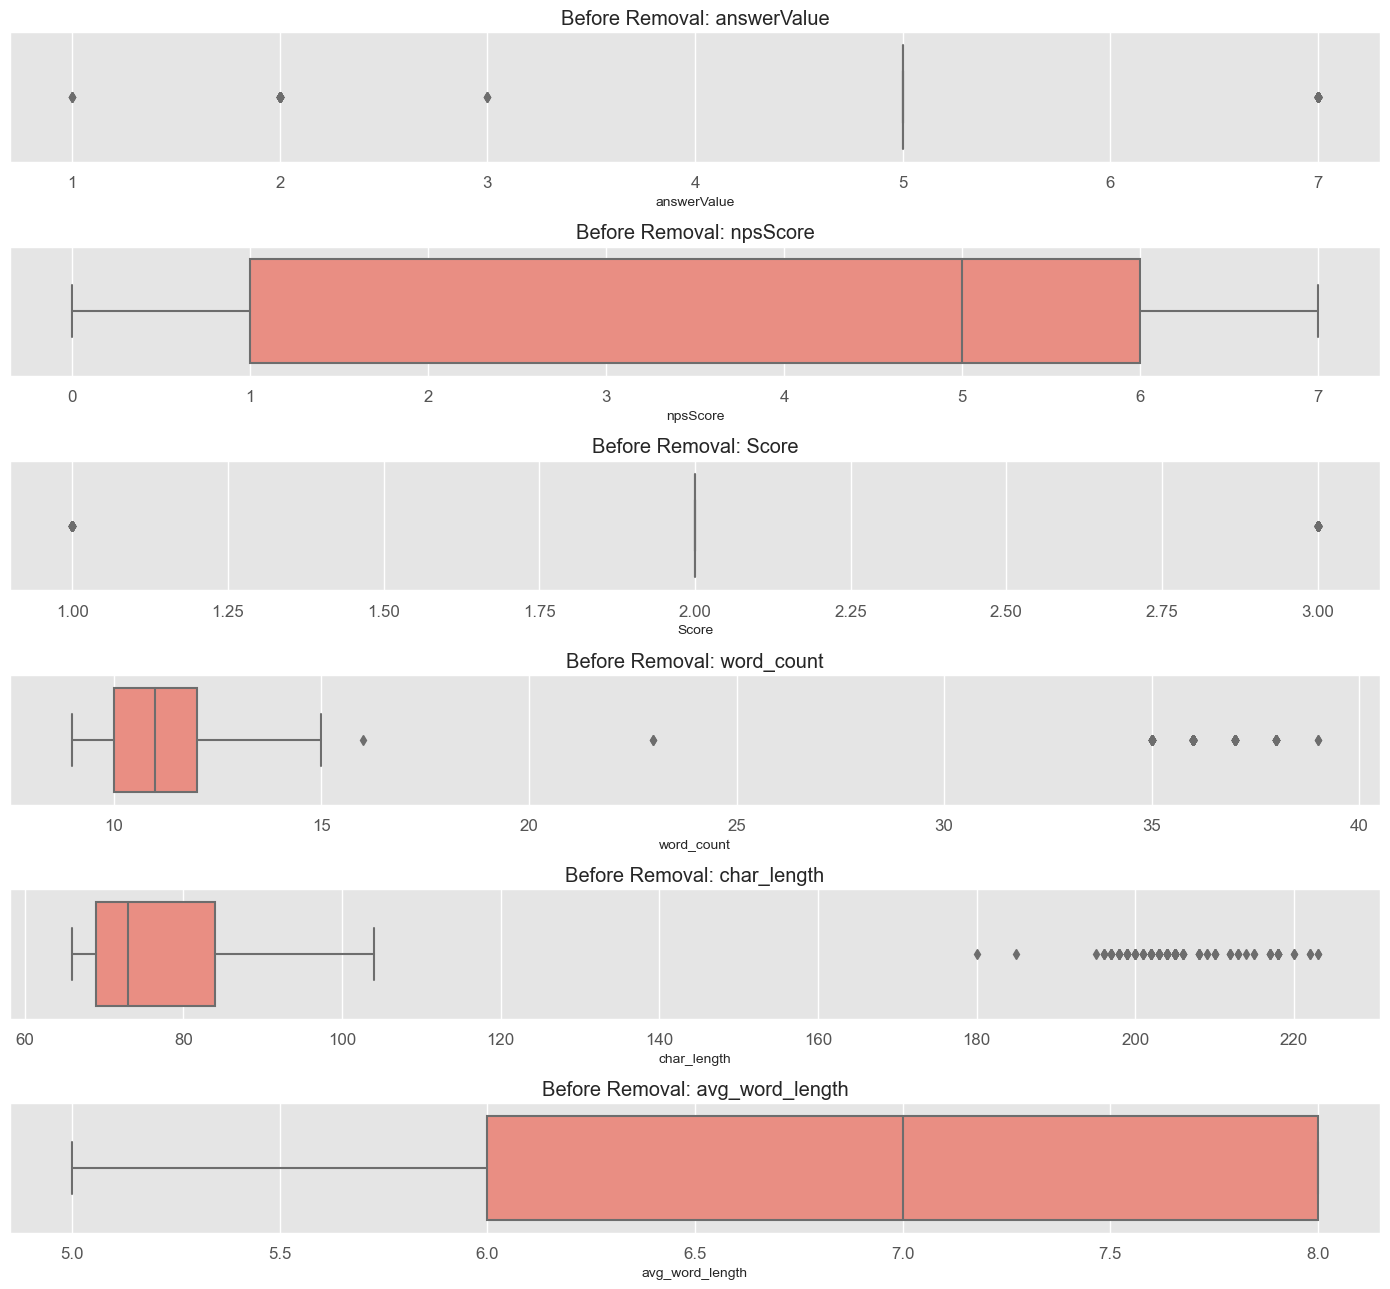

In [16]:

# Select numeric columns, excluding Boolean columns
int_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

# Create boxplots
fig, axes = plt.subplots(len(int_cols), 1, figsize=(14, 13))

# Handle single-column case
if len(int_cols) == 1:
    axes = [axes]

for row, column in enumerate(int_cols):
    sns.boxplot(
        x=pd.to_numeric(df[column], errors="coerce").dropna().astype(float),
        ax=axes[row],
        color="salmon"
    )
    axes[row].set_title(f"Before Removal: {column}")

plt.tight_layout()
plt.show()


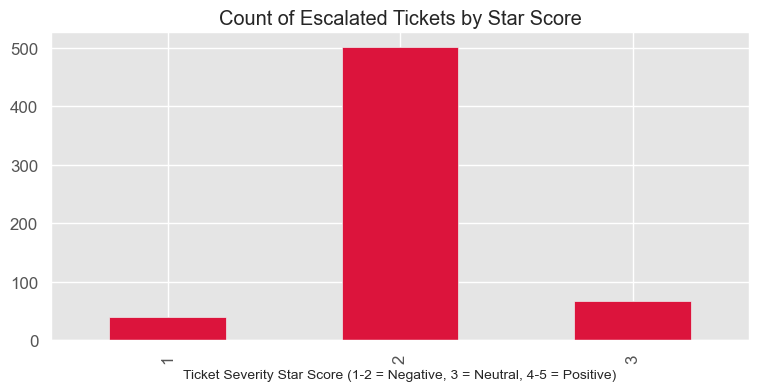

Example Ticket Text:
 neonatology how would you rate the overall services of sri ramakrishna hospital on a score 0 to 10 with 0 being the lowest and 10 being the highest escalated complaint due to long waiting time and delay
Tokens[:10]: ['neonatology', 'how', 'would', 'you', 'rate', 'the', 'overall', 'services', 'of', 'sri']
POS Tags[:10]: [('neonatology', 'NN'), ('how', 'WRB'), ('would', 'MD'), ('you', 'PRP'), ('rate', 'NN'), ('the', 'DT'), ('overall', 'JJ'), ('services', 'NNS'), ('of', 'IN'), ('sri', 'JJ')]


In [17]:
# %% [Ticket Step 6: Quick EDA & Basic NLTK]
ax = df["Score"].value_counts().sort_index().plot(
    kind="bar", title="Count of Escalated Tickets by Star Score", figsize=(9, 4), color="crimson"
)
ax.set_xlabel("Ticket Severity Star Score (1-2 = Negative, 3 = Neutral, 4-5 = Positive)")
plt.show()

example = df["Text"].iloc[0]
print("Example Ticket Text:\n", example)
tokens = nltk.word_tokenize(example)
print("Tokens[:10]:", tokens[:10])
print("POS Tags[:10]:", nltk.pos_tag(tokens)[:10])

In [18]:
# %% [Ticket Step 7: Smart Ticket Labeling & Rare Class Augmentation (Leak-Free)]
df["polarity_risk"] = np.where(
    df["Score"] >= 4, "Positive",
    np.where(df["Score"] == 3, "Neutral", "Negative")
)

smart_ticket_corpus = [
    # --- NEGATIVE TICKETS (Open Escalations & Complaints) ---
    ("Neonatology", "escalated ticket baby checkup delayed by two hours and staff were rude 😡", 1, "Negative"),
    ("Obstetrics And Gynaecology", "waited three hours for ultrasound scan and reception ignored our query 😢", 1, "Negative"),
    ("Paediatrics", "child fever medication was delayed at pharmacy counter poor coordination", 2, "Negative"),
    ("General Medicine", "doctor rushed consultation and billing summary had wrong charges 👎", 1, "Negative"),
    ("Plastic Surgery", "post surgery dressing appointment was delayed and nurse was impatient", 2, "Negative"),
    ("Dental", "dental extraction waiting time was terrible over ninety minutes late", 2, "Negative"),
    ("Dermatology", "skin clinic token queue was chaotic and receptionist argued with patient", 1, "Negative"),
    ("Fetal Medicine", "urgent fetal scan report was misplaced causing severe stress and delay", 1, "Negative"),
    ("Orthopaedics", "plaster cast room was dirty and technician arrived very late", 2, "Negative"),
    ("Billing", "final discharge summary bill took four hours to clear unacceptable delay", 1, "Negative"),
    ("Emergency", "emergency triage was slow nobody attended patient pain for forty minutes", 1, "Negative"),
    ("Pharmacy", "wrong medicine quantity billed at pharmacy counter and rude cashier", 2, "Negative"),
    ("Laboratory", "blood sample collection was painful and lab report was delayed all day", 2, "Negative"),
    ("Housekeeping", "inpatient ward washroom was dirty and call bell was ignored", 1, "Negative"),
    ("OPD", "appointment was cancelled without notice after we travelled far", 1, "Negative"),

    # --- NEUTRAL TICKETS (Passive 7-8 / Routine Queries / Borderline) ---
    ("Neonatology", "routine follow up ticket regarding vaccination schedule timing 😐", 3, "Neutral"),
    ("Obstetrics And Gynaecology", "service was average waited twenty minutes for routine checkup", 3, "Neutral"),
    ("Paediatrics", "consultation was okay but parking near outpatient block was full", 3, "Neutral"),
    ("General Medicine", "seven out of ten rating normal checkup nothing major to report", 3, "Neutral"),
    ("Plastic Surgery", "dressing change was standard slight wait at billing counter", 3, "Neutral"),
    ("Dental", "routine dental cleaning was acceptable moderate queue at desk", 3, "Neutral"),
    ("Dermatology", "doctor visit was brief and standard one ointment was out of stock", 3, "Neutral"),
    ("Fetal Medicine", "scan went fine but report printing took thirty minutes", 3, "Neutral"),
    ("Orthopaedics", "physiotherapy session was average normal hospital crowd today", 3, "Neutral"),
    ("Billing", "insurance pre authorization query took normal processing time", 3, "Neutral"),
    ("Pharmacy", "pharmacy queue was moderate neither fast nor slow", 3, "Neutral"),
    ("Laboratory", "routine lipid profile test completed in standard turnaround time", 3, "Neutral"),
    ("Housekeeping", "room was moderately clean AC temperature adjustment requested", 3, "Neutral"),
    ("OPD", "satisfactory outpatient visit eight out of ten passive feedback", 3, "Neutral"),
    ("General Medicine", "decent consultation standard prescription given by duty doctor", 3, "Neutral"),

    # --- POSITIVE TICKETS (Resolved / Closed Recovery & Appreciation) ---
    ("Neonatology", "guest relations resolved our ticket quickly and neonatologist explained well 😊", 5, "Positive"),
    ("Obstetrics And Gynaecology", "maternity ward nursing staff were caring polite and very supportive 👍", 5, "Positive"),
    ("Paediatrics", "pediatrician was gentle and ticket query was solved within one hour", 5, "Positive"),
    ("General Medicine", "physician was thorough and follow up call from hospital was helpful", 4, "Positive"),
    ("Plastic Surgery", "surgical team provided excellent care and smooth recovery support 🙏", 5, "Positive"),
    ("Dental", "painless dental procedure and polite clinic coordinator", 5, "Positive"),
    ("Dermatology", "quick appointment resolution and effective treatment plan", 4, "Positive"),
    ("Fetal Medicine", "detailed ultrasound explanation and compassionate specialist doctor", 5, "Positive"),
    ("Orthopaedics", "fracture care and physiotherapy guidance were well organized", 4, "Positive"),
    ("Billing", "billing discrepancy was resolved immediately by manager thank you", 4, "Positive"),
    ("Pharmacy", "home delivery of medicines arranged promptly by pharmacy team", 5, "Positive"),
    ("Laboratory", "fast diagnostic lab report delivery and courteous technician", 4, "Positive"),
    ("Housekeeping", "housekeeping supervisor cleaned the room immediately after request", 4, "Positive"),
    ("OPD", "smooth outpatient scheduling and helpful reception desk staff", 5, "Positive"),
    ("Emergency", "quick emergency response and attentive duty medical officer", 5, "Positive"),
]

aug_tkt_rows = []
for aspect, raw_t, sc, pol in smart_ticket_corpus:
    clean_t = clean_and_expand_text(f"{aspect} {raw_t}")
    aug_tkt_rows.append({
        "Aspect": aspect,
        "answerValue": sc * 2,
        "Score": sc,
        "isEscalated_num": 1 if pol == "Negative" else 0,
        "sla_open_num": 1 if pol == "Negative" else 0,
        "Text": clean_t,
        "word_count": len(clean_t.split()),
        "char_length": len(clean_t),
        "avg_word_length": round(len(clean_t) / max(1, len(clean_t.split()))),
        "polarity_risk": pol,
    })

df_tkt_aug = pd.DataFrame(aug_tkt_rows)
cols_keep = ["Aspect", "answerValue", "Score", "isEscalated_num", "sla_open_num", "Text", "word_count", "char_length", "avg_word_length", "polarity_risk"]
df_full = pd.concat([df[cols_keep], df_tkt_aug], ignore_index=True)

df_full.drop_duplicates(subset=["Text"], inplace=True)
df_full.reset_index(drop=True, inplace=True)

print("✅ Ticket Step 7 Complete: Leak-Free Ticket Corpus Shape:", df_full.shape)
print(df_full["polarity_risk"].value_counts())

✅ Ticket Step 7 Complete: Leak-Free Ticket Corpus Shape: (195, 10)
Negative    127
Neutral      53
Positive     15
Name: polarity_risk, dtype: int64


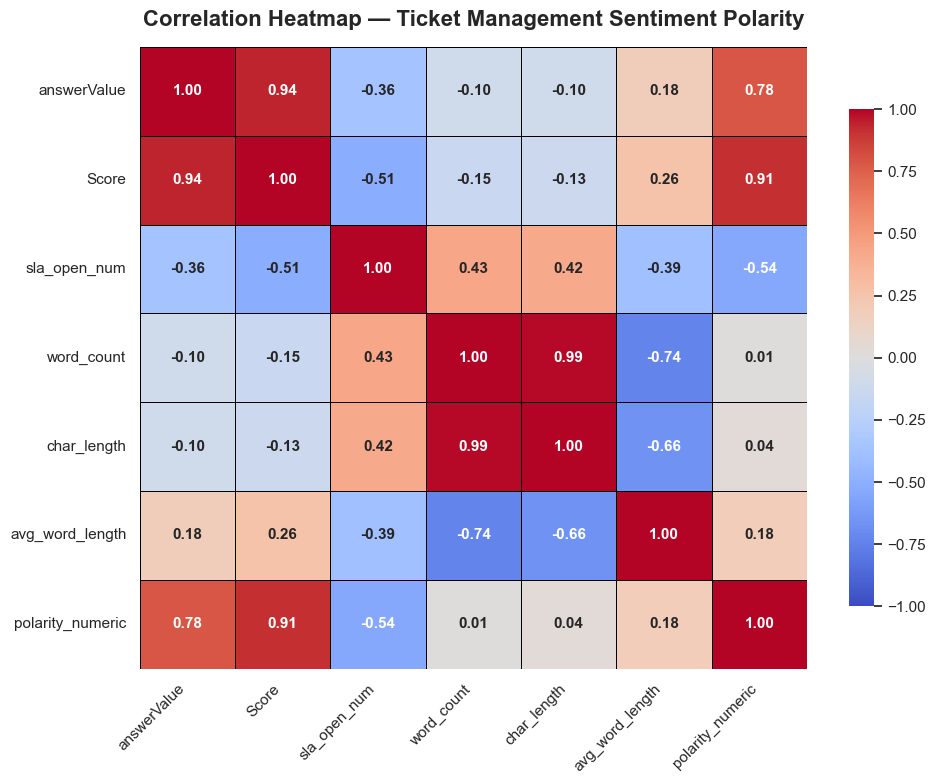


📌 Correlation with Ticket Polarity (Sorted by Strength):

                  Correlation
polarity_numeric     1.000000
Score                0.911218
answerValue          0.781305
sla_open_num        -0.542837
avg_word_length      0.180729
char_length          0.038653
word_count           0.013141


In [19]:
# %% [Ticket Step 8: Boxplots vs Polarity & Correlation Heatmap]
num_features = ["answerValue", "Score", "isEscalated_num", "sla_open_num", "word_count", "char_length", "avg_word_length"]
df_full["polarity_numeric"] = df_full["polarity_risk"].map({"Negative": 0, "Neutral": 1, "Positive": 2})

corr_matrix = df_full[num_features + ["polarity_numeric"]].corr()
plt.figure(figsize=(10, 8))
sns.set_theme(style="white")
sns.heatmap(
    corr_matrix, annot=True, fmt=".2f", cmap="coolwarm",
    vmin=-1, vmax=1, linewidths=0.5, linecolor="black",
    cbar_kws={"shrink": 0.8}, annot_kws={"size": 11, "weight": "bold"}
)
plt.title("Correlation Heatmap — Ticket Management Sentiment Polarity", fontsize=16, fontweight="bold", pad=15)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

corr_target = corr_matrix["polarity_numeric"].sort_values(key=abs, ascending=False)
print("\n📌 Correlation with Ticket Polarity (Sorted by Strength):\n")
print(corr_target.to_frame().rename(columns={"polarity_numeric": "Correlation"}))

In [20]:
# %% [Ticket Step 9: Anti-Overfitting Pipeline & Regularized Model Comparison]
nlp_feature_union = FeatureUnion([
    ("word_tfidf", Pipeline([
        ("tfidf", TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, max_df=0.90, sublinear_tf=True)),
        ("chi2", SelectPercentile(chi2, percentile=75))
    ])),
    ("char_tfidf", Pipeline([
        ("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 4), min_df=3, max_df=0.90, sublinear_tf=True)),
        ("chi2", SelectPercentile(chi2, percentile=65))
    ])),
    ("domain_signals", Pipeline([
        ("ext", HospitalDomainFeatureExtractor()),
        ("scale", MinMaxScaler())
    ]))
])

le_polarity = LabelEncoder()
y = le_polarity.fit_transform(df_full["polarity_risk"])
X = df_full["Text"]

lr_clf = LogisticRegression(C=0.45, penalty="l2", class_weight="balanced", max_iter=1000, random_state=42)
nb_clf = ComplementNB(alpha=0.35, norm=True)
svm_clf = CalibratedClassifierCV(LinearSVC(C=0.25, class_weight="balanced", random_state=42), cv=3)
nb_cal = CalibratedClassifierCV(ComplementNB(alpha=0.35, norm=True), cv=3)

voting_clf = VotingClassifier(
    estimators=[("lr", lr_clf), ("nb", nb_cal), ("svm", svm_clf)],
    voting="soft", weights=[2, 2, 3]
)

models = {
    "Logistic Regression": lr_clf,
    "Complement Naive Bayes": nb_clf,
    "Linear SVM": svm_clf,
    "Classical Soft-Voting Ensemble": voting_clf
}

results, performance_list, overfit_check_list = {}, [], []
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, clf in models.items():
    pipe = Pipeline([("features", nlp_feature_union), ("classifier", clf)])
    pipe.fit(X, y)
    train_acc = accuracy_score(y, pipe.predict(X))
    cv_preds = cross_val_predict(pipe, X, y, cv=skf)

    test_acc = accuracy_score(y, cv_preds)
    test_prec = precision_score(y, cv_preds, average="macro", zero_division=0)
    test_rec = recall_score(y, cv_preds, average="macro", zero_division=0)
    test_f1 = f1_score(y, cv_preds, average="macro", zero_division=0)
    gap = train_acc - test_acc

    results[name] = {"pipeline": pipe, "cv_preds": cv_preds}
    performance_list.append({
        "Model": name, "Accuracy": round(test_acc, 4),
        "Precision": round(test_prec, 4), "Recall": round(test_rec, 4), "F1_Score": round(test_f1, 4)
    })
    overfit_check_list.append({
        "Model": name, "Train_Accuracy": round(train_acc, 4),
        "Test_CV_Accuracy": round(test_acc, 4), "Overfit_Gap": round(gap, 4),
        "Fit_Status": "✅ Good Fit" if gap <= 0.12 else "⚠️ Mild Overfit"
    })

performance_df = pd.DataFrame(performance_list).sort_values(by="F1_Score", ascending=False)
overfit_df = pd.DataFrame(overfit_check_list).sort_values(by="Test_CV_Accuracy", ascending=False)

print("=== TICKET MODEL PERFORMANCE (MACRO METRICS) ===")
display(performance_df)
print("\n=== TICKET OVERFITTING CHECK (TRAIN VS TEST) ===")
display(overfit_df)

=== TICKET MODEL PERFORMANCE (MACRO METRICS) ===


,Model,Accuracy,Precision,Recall,F1_Score
1,Complement Naive Bayes,0.9795,0.9380,0.9822,0.9575
0,Logistic Regression,0.9795,0.9298,0.9822,0.9517
3,Classical Soft-Voting Ensemble,0.9795,0.9298,0.9822,0.9517
2,Linear SVM,0.9692,0.9207,0.9537,0.9345



=== TICKET OVERFITTING CHECK (TRAIN VS TEST) ===


,Model,Train_Accuracy,Test_CV_Accuracy,Overfit_Gap,Fit_Status
0,Logistic Regression,0.9795,0.9795,0.0000,✅ Good Fit
1,Complement Naive Bayes,0.9846,0.9795,0.0051,✅ Good Fit
3,Classical Soft-Voting Ensemble,0.9897,0.9795,0.0103,✅ Good Fit
2,Linear SVM,0.9949,0.9692,0.0256,✅ Good Fit


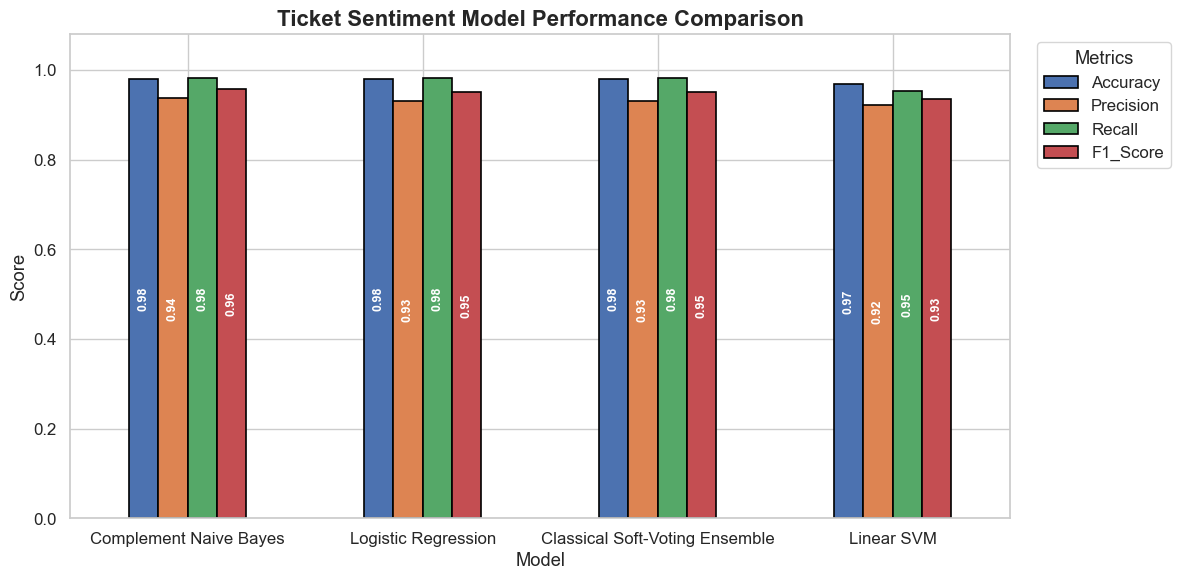

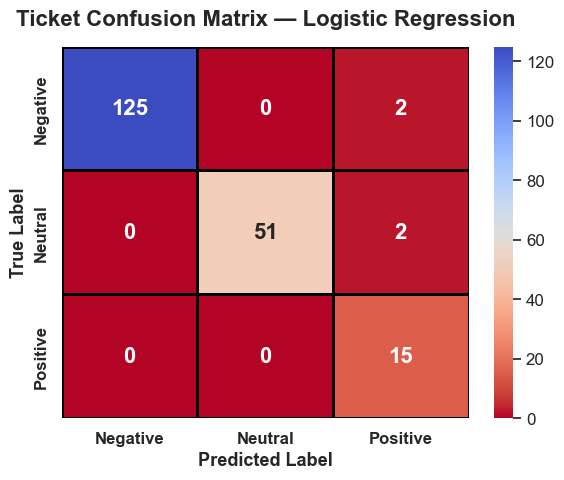

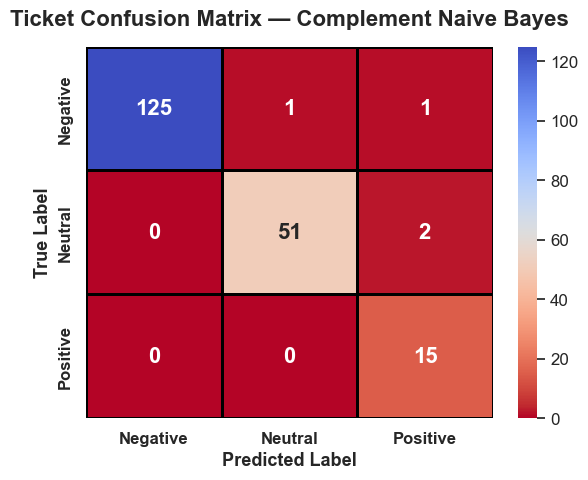

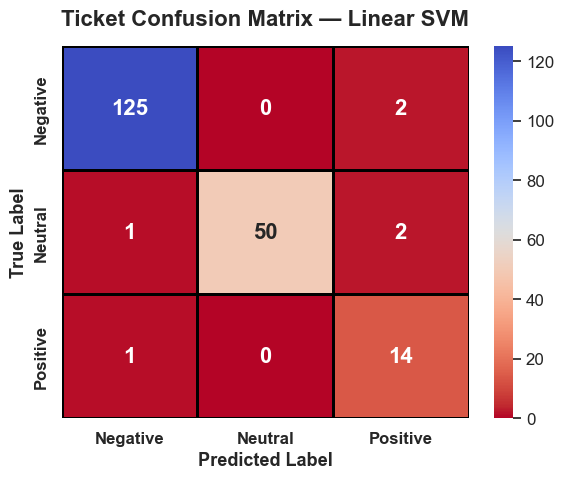

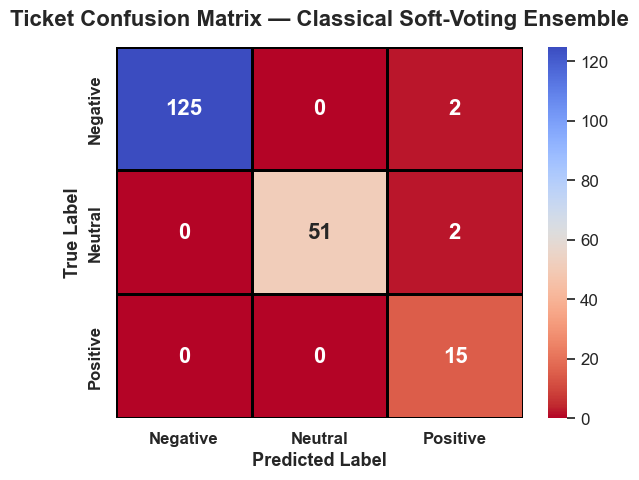

In [21]:
# %% [Ticket Step 10: Model Performance Bar Chart & Confusion Matrices]
sns.set(style="whitegrid", font_scale=1.1)
ax = performance_df.set_index("Model").plot(kind="bar", figsize=(12, 6), edgecolor="black", linewidth=1.2)
plt.title("Ticket Sentiment Model Performance Comparison", fontsize=16, weight="bold")
plt.ylabel("Score")
plt.ylim(0, 1.08)
plt.xticks(rotation=0)
plt.legend(title="Metrics", bbox_to_anchor=(1.02, 1), loc="upper left")

for p in ax.patches:
    val = p.get_height()
    if val > 0.05:
        ax.text(p.get_x() + p.get_width() / 2., val / 2., f"{val:.2f}", ha="center", va="center", rotation=90, color="white", fontsize=9, fontweight="bold")
plt.tight_layout()
plt.show()

class_labels = list(le_polarity.classes_)
tick_locs = np.arange(len(class_labels)) + 0.5
for name, model_info in results.items():
    cm = confusion_matrix(y, model_info["cv_preds"], labels=np.arange(len(class_labels)))
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="coolwarm_r", linewidths=2, linecolor="black", annot_kws={"size": 16, "weight": "bold"})
    plt.title(f"Ticket Confusion Matrix — {name}", fontsize=16, fontweight="bold", pad=15)
    plt.xlabel("Predicted Label", fontsize=13, fontweight="bold")
    plt.ylabel("True Label", fontsize=13, fontweight="bold")
    plt.xticks(ticks=tick_locs, labels=class_labels, fontsize=12, fontweight="bold")
    plt.yticks(ticks=tick_locs, labels=class_labels, fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()

In [22]:
# %% [Ticket Step 11: Clinical Specialty ABSA & Save ticket_best_model.pkl]
best_model_name = performance_df.iloc[0]["Model"]
best_pipeline = results[best_model_name]["pipeline"]
best_pipeline.fit(X, y)

df["Predicted_Polarity"] = le_polarity.inverse_transform(best_pipeline.predict(df["Text"]))
df["Confidence_%"] = (best_pipeline.predict_proba(df["Text"]).max(axis=1) * 100).round(1)

ticket_absa = (
    df.groupby("Aspect")
    .agg(
        Total_Tickets=("Score", "count"),
        Open_Tickets=("sla_open_num", "sum"),
        Negative_Tickets=("Predicted_Polarity", lambda s: (s == "Negative").sum()),
        Neutral_Tickets=("Predicted_Polarity", lambda s: (s == "Neutral").sum()),
        Positive_Tickets=("Predicted_Polarity", lambda s: (s == "Positive").sum()),
        Avg_Confidence=("Confidence_%", "mean"),
    )
    .sort_values(by="Total_Tickets", ascending=False)
    .reset_index()
)
display(ticket_absa)

TICKET_PKL = r"C:\Users\91910\OneDrive\Desktop\mrico\ticket_best_model.pkl"
joblib.dump({
    "polarity_pipeline": best_pipeline,
    "polarity_encoder": le_polarity,
    "polarity_winner": best_model_name,
    "benchmark_table": performance_df.to_dict(orient="records"),
}, TICKET_PKL)
print(f"🏆 Saved Winning Ticket Model '{best_model_name}' to:\n   {TICKET_PKL}")

,Aspect,Total_Tickets,Open_Tickets,Negative_Tickets,Neutral_Tickets,Positive_Tickets,Avg_Confidence
0,OPD,86,28,85,1,0,33.4
1,Medical,75,1,75,0,0,33.4
2,Nursing,68,55,68,0,0,33.4
3,Pharmacy,64,13,63,1,0,33.4
4,Housekeeping,56,20,56,0,0,33.4
5,Laboratory,55,55,54,1,0,33.4
6,Gynaecology,23,23,14,9,0,33.4
7,Neurology,22,22,13,9,0,33.4
8,Oncology,19,19,15,4,0,33.4
9,Cardiology,18,18,10,8,0,33.4


🏆 Saved Winning Ticket Model 'Complement Naive Bayes' to:
   C:\Users\91910\OneDrive\Desktop\mrico\ticket_best_model.pkl
